In [4]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from sklearn.cluster import KMeans

## 請安裝
> pip install opencv-python

# Problem : K-Means Clustering
**K-Means Clustering** is an unsupervised learning algorithm for data grouping. In image segmen- tation, it can be applied to partition image pixels into different groups based on the associated pixel values or features. In this problem, you will learn how to segment the provided image by using K-means clustering.

In [5]:
img = cv2.imread('data/bird.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

## 1-1. cluster with only RGB values

In [10]:
def km_clust(array, n_clusters):   
    # Define the k-means clustering problem
    k_m = KMeans(n_clusters = n_clusters)
    # Solve the k-means clustering problem
    k_m.fit(array)
    # Get the coordinates of the clusters centres
    center = k_m.cluster_centers_
    print(center)
    # Get the label of each point
    label = k_m.labels_
    return(label, center)

In [12]:
# 取得圖片的高度 (h)、寬度 (w) 和顏色通道數 (c)
h, w, c = img.shape

# 印出圖片的原始尺寸（目前已註解）
# print(img.shape)

# 將圖片從三維陣列轉換為二維陣列
# -1：自動計算像素總數 (h × w)
# 3：每個像素有 3 個顏色通道 (RGB 或 BGR)
Z = img.reshape((-1, 3))

# 設定 K-Means 分群數量為 2
K = 2

# 執行 K-Means 分群
# label：每個像素所屬的群組編號
# center：每個群組的中心顏色值
label, center = km_clust(Z, K)

# 將群組中心的顏色數值轉換為 uint8（0～255 的整數）
# center[:, :3]：取出所有群組的前三個顏色通道
# np.uint8()：轉換成圖片常用的 8-bit 無號整數格式
center = np.uint8(center[:, :3])

# 顯示分群後的中心顏色數值
center

[[107.75453816  95.62058252  71.64649253]
 [163.22895318 197.73825666 120.58773586]]


array([[107,  95,  71],
       [163, 197, 120]], dtype=uint8)

[[163.20459253 197.61786527 120.55675622]
 [107.25143942  95.16386349  71.26159275]]


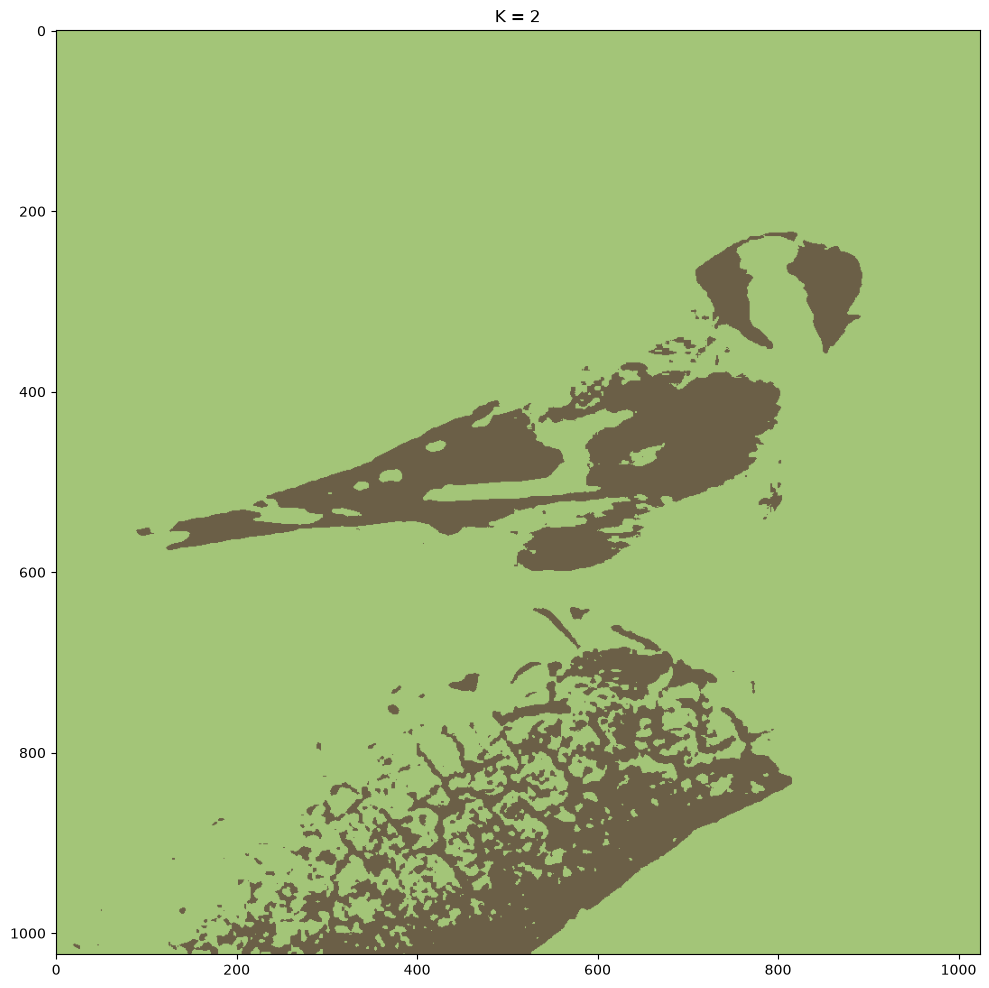

In [19]:
# # 取得圖片的高度 (h)、寬度 (w) 和顏色通道數 (c)
# h, w, c = img.shape

# # 顯示圖片的原始尺寸（目前已註解）
# # print(img.shape)

# # 將三維圖片轉換成二維陣列
# # -1：由 NumPy 自動計算像素總數 (h × w)
# # 3：每個像素包含 3 個顏色通道 (RGB 或 BGR)
# Z = img.reshape((-1, 3))

# # 設定 K-Means 分群數量為 2
# # 代表將圖片的像素分成 2 個顏色群組
# K = 2

# # 執行 K-Means 分群
# # label：每個像素所屬的群組編號
# # center：每個群組的中心顏色值
# label, center = km_clust(Z, K)

# # 將分群中心的顏色數值轉換成 uint8 格式
# # center[:, :3]：取得所有群組的前三個顏色通道
# center = np.uint8(center[:, :3])

# # 根據每個像素的群組編號，取得對應的中心顏色
# # label.flatten()：將群組標籤轉成一維陣列
# res = center[label.flatten()]

# # 將二維像素資料還原成原始圖片的三維形狀
# res = res.reshape(img.shape)

# # 建立新的繪圖視窗，設定圖片顯示尺寸為 16 × 12 英吋
# plt.figure(figsize=(16, 12))

# # 設定圖片標題，顯示 K-Means 分群數量
# plt.title("K = {}".format(K))

# # 顯示 K-Means 分群後重建的圖片
# plt.imshow(res)

[[163.20453914 197.61743823 120.55661966]
 [107.2494617   95.16228803  71.26040656]]
[[183.99977201 182.80300943 164.99303689]
 [ 58.43076681  55.24643356  46.16091773]
 [160.65542964 204.76118537 114.71514118]
 [143.9719108  128.34048888  97.25867181]]


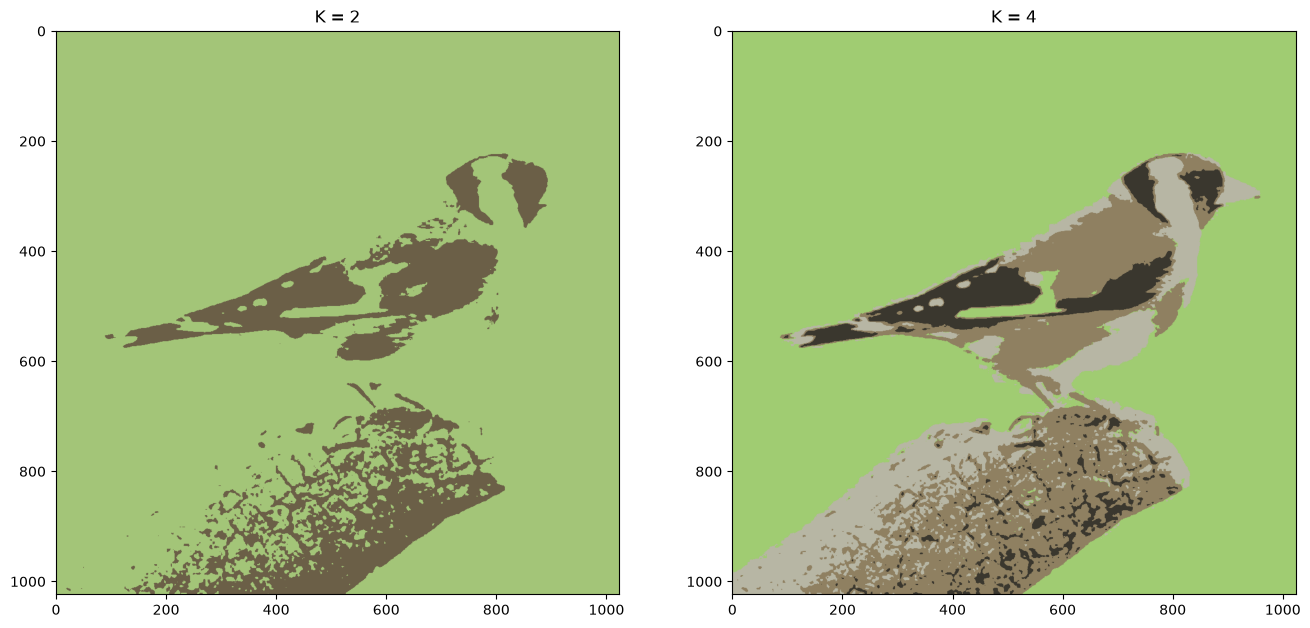

In [20]:
# 取得圖片的高度 (h)、寬度 (w) 和顏色通道數 (c)
h, w, c = img.shape

# 顯示原始圖片尺寸（目前已註解）
# print(img.shape)

# 將三維圖片轉換成二維陣列
# -1：自動計算像素總數 (h × w)
# 3：每個像素具有 3 個顏色通道 (RGB 或 BGR)
Z = img.reshape((-1, 3))

# 設定要比較的 K-Means 分群數量
# K=2：使用 2 個代表顏色
# K=4：使用 4 個代表顏色
Ka = [2, 4]

# 建立圖片顯示視窗，大小為 16 × 12 英吋
plt.figure(figsize=(16, 12))

# 使用迴圈，依序執行 K=2 和 K=4 的分群
# i：迴圈索引 (0、1)
# K：目前的分群數量 (2、4)
for i, K in enumerate(Ka):

    # 執行 K-Means 分群
    # label：每個像素所屬的群組編號
    # center：每個群組的中心顏色
    label, center = km_clust(Z, K)

    # 將中心顏色轉換成 uint8 格式
    # center[:, :3]：取出所有群組的前三個顏色通道
    center = np.uint8(center[:, :3])

    # 根據像素所屬的群組，取得對應的中心顏色
    # label.flatten()：將群組標籤轉成一維陣列
    res = center[label.flatten()]

    # 將像素資料還原為原始圖片的三維形狀
    res = res.reshape(img.shape)

    # 建立子圖
    # 1：一列
    # len(Ka)：兩欄
    # i+1：目前子圖的位置 (1、2)
    plt.subplot(1, len(Ka), i+1)

    # 設定子圖標題，顯示目前的 K 值
    plt.title("K = {}".format(K))

    # 顯示目前 K 值的分群結果圖片
    plt.imshow(res)

# 顯示所有圖片
plt.show()

[[126.97277335 192.00156879]
 [128.77339728  64.02060751]]
[[192.33228564  64.4480412 ]
 [ 63.4064492  191.29959307]
 [191.39983044 192.44124235]
 [ 64.33951381  63.30408874]]
[[ 59.79581604  36.43717337]
 [212.23625975 213.90334266]
 [ 42.59238493 213.0133669 ]
 [196.9404492   37.12914806]
 [128.2145536  100.40016254]
 [127.02808159 202.81100028]
 [ 42.1544476  124.12313852]
 [213.51869041 126.07278941]]
[[225.96761    224.32836841]
 [156.85686078  89.83989863]
 [ 91.47636862 170.84888132]
 [ 32.30996685  29.39044826]
 [160.89053557  29.09787914]
 [ 32.02007058  90.37721344]
 [222.24472872 160.72773649]
 [101.56271574 228.0129032 ]
 [222.48685564  97.25588685]
 [ 93.83340558 106.36423564]
 [155.66310909 154.62524115]
 [ 33.20083887 222.93628641]
 [ 30.16841278 155.34165563]
 [224.44117468  32.62379509]
 [164.85165847 221.15408639]
 [ 96.39720311  35.85554284]]
[[ 18.29182166 191.8198382 ]
 [151.05624001 102.80970407]
 [153.79115625 199.6440639 ]
 [ 60.15245876  64.99371034]
 [233.6020

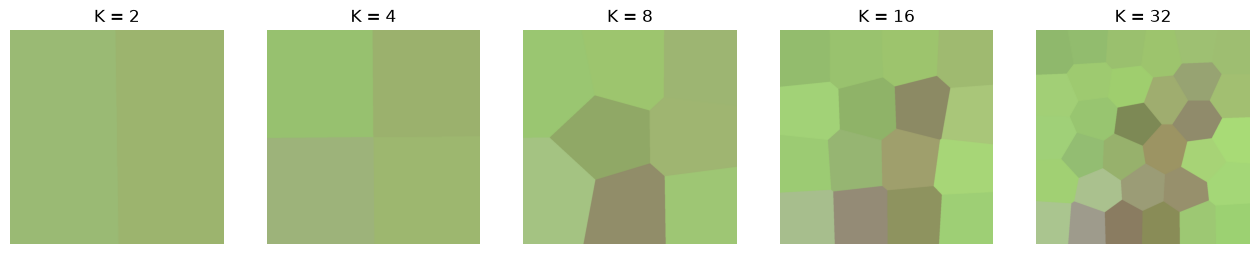

In [24]:

# ============================================================
# 【第一部分】取得圖片尺寸（Image Shape）
# ============================================================

# h：圖片高度
# w：圖片寬度
# c：圖片顏色通道數
h, w, c = img.shape


# ============================================================
# 【第二部分】建立位置特徵陣列（Position Only）
# ============================================================

# 建立全為 0 的三維陣列
# 每個像素只保留兩個特徵：高度座標、寬度座標
Z = np.zeros((h, w, 2))

# 逐列讀取圖片像素
for h in range(len(img)):

    # 逐欄讀取圖片像素
    for w in range(len(img[h])):

        # 只儲存位置座標，不使用 RGB
        Z[h][w] = [h/4, w/4]

# 將三維陣列轉成二維陣列
# 2：每個像素只有兩個位置特徵
Z = Z.reshape(-1, 2)


# ============================================================
# 【第三部分】設定 K-Means 分群數量
# ============================================================

# 比較五種不同 K 值
Ks = [2,4,8,16,32]

# 建立圖片顯示視窗
plt.figure(figsize=(16,12))


# ============================================================
# 【第四部分】執行 K-Means 位置分群
# ============================================================

# i：子圖索引
# K：目前使用的分群數量
for i, K in enumerate(Ks):

    # 根據像素位置進行 K-Means 分群
    # label：每個像素的群組編號
    # center：各群組的中心座標
    label, center = km_clust(Z, K)


    # ========================================================
    # 【第五部分】將分群結果轉換成圖片
    # ========================================================

    # 將每個群組內的像素用原圖平均顏色表示
    # 注意：RGB 只用來顯示，不參與 K-Means 分群
    colors = np.zeros((K, 3))

    # 將原始圖片轉成二維像素資料
    pixels = img.reshape(-1, 3)

    # 計算每個位置群組的平均 RGB 顏色
    for j in range(K):
        colors[j] = pixels[label.flatten() == j].mean(axis=0)

    # 轉換成 uint8 圖片格式
    colors = np.uint8(colors)

    # 根據每個像素的群組，指定代表顏色
    res = colors[label.flatten()]

    # 還原成原始圖片尺寸
    res = res.reshape(img.shape)


    # ========================================================
    # 【第六部分】顯示不同 K 值的分群結果
    # ========================================================

    # 建立 1 列、5 欄的子圖
    plt.subplot(1, 5, i+1)

    # 關閉座標軸
    plt.axis('off')

    # 顯示目前 K 值
    plt.title("K = {}".format(K))

    # 顯示位置分群後的圖片
    plt.imshow(res)


# ============================================================
# 【第七部分】顯示所有圖片
# ============================================================

plt.show()


## 1-2. cluster with RGB values and the location

[[163.20459253 197.61786527 120.55675622]
 [107.25143942  95.16386349  71.26159275]]
[[160.64867397 204.7663149  114.70092225]
 [143.5051542  127.83292534  96.68200829]
 [ 57.40265718  54.4473187   45.84565445]
 [183.67841726 182.36618589 164.39008177]]
[[160.62502428 205.10737952 114.63757832]
 [130.91323401 112.46441353  76.2795428 ]
 [165.03831375 156.31284535 132.74969832]
 [ 93.33670997  81.8103251   57.38628256]
 [181.65678456 184.54560622 162.32335955]
 [ 32.08861496  35.90876695  38.91527581]
 [209.02886029 209.04769964 201.61769029]
 [150.35467039 135.92567167 104.49733177]]
[[177.89628648 179.19597044 153.54729039]
 [108.781424    97.69477311  67.95841453]
 [157.37318805 195.34018899 111.56779996]
 [140.92802376 130.41051043 108.60686902]
 [ 25.11010202  26.78533939  26.11700183]
 [163.4544031  212.21450279 117.59937455]
 [192.15724085 193.9366557  180.80195282]
 [163.82886767 144.10564181 106.92805565]
 [133.71810393 117.39224337  81.98437901]
 [228.86586155 203.2971749   37

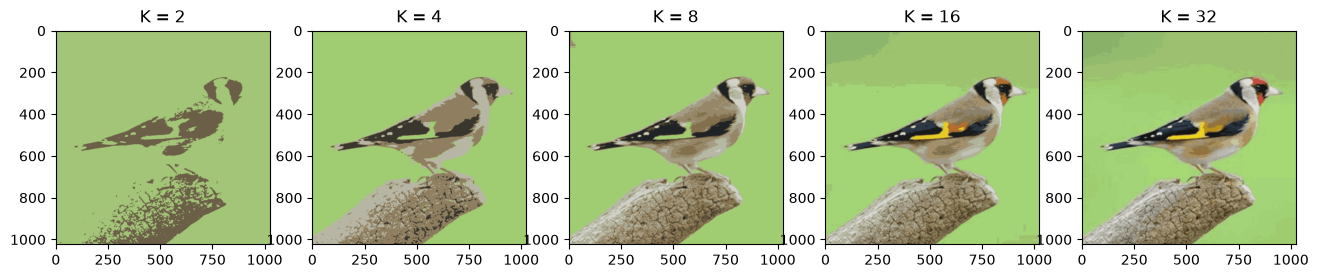

In [23]:

# ============================================================
# 【第一部分】取得圖片尺寸（Image Information）
# ============================================================

# h：圖片高度，w：圖片寬度，c：顏色通道數
h, w, c = img.shape

# 顯示圖片尺寸（目前已註解）
#print(img.shape)


# ============================================================
# 【第二部分】轉換圖片資料（Data Reshaping）
# ============================================================

# 將原本三維圖片轉換成二維陣列
# -1：自動計算像素總數 (h × w)
# 3：每個像素包含 3 個顏色通道 (RGB 或 BGR)
Z = img.reshape((-1,3))


# ============================================================
# 【第三部分】設定 K-Means 分群數量
# ============================================================

# 設定要比較的五種分群數量：2、4、8、16、32
Ka = [2,4,8,16,32]

# 建立繪圖視窗，大小為 16 × 12 英吋
plt.figure(figsize=(16,12))


# ============================================================
# 【第四部分】執行 K-Means 分群
# ============================================================

# enumerate(Ka)：依序取得索引 i 和分群數量 K
# i：0、1、2、3、4
# K：2、4、8、16、32
for i,K in enumerate(Ka):

    # 執行 K-Means 分群
    # label：每個像素所屬的群組編號
    # center：各群組的中心顏色
    label, center = km_clust(Z, K)


    # ========================================================
    # 【第五部分】將分群結果轉換回圖片格式
    # ========================================================

    # 原始英文註解：轉回 uint8 格式並重建圖片
    # Now convert back into uint8, and make original image

    # 取出群組中心的前三個顏色通道
    # np.uint8：轉換成 8-bit 無號整數
    center = np.uint8(center[:,:3])

    # 將每個像素替換成所屬群組的中心顏色
    # label.flatten()：將群組標籤展平成一維
    res = center[label.flatten()]

    # 將二維像素資料還原成原始圖片形狀
    res = res.reshape(img.shape)


    # ========================================================
    # 【第六部分】繪製不同 K 值的分群圖片
    # ========================================================

    # 建立 1 列、len(Ka) 欄的子圖
    # i+1：目前圖片的位置，從 1 開始
    plt.subplot(1,len(Ka),i+1)

    # 設定圖片標題，顯示目前 K 值
    plt.title("K = {}".format(K))

    # 顯示分群後的圖片
    plt.imshow(res)


# ============================================================
# 【第七部分】顯示所有圖片
# ============================================================

# 一次顯示 K=2、4、8、16、32 的分群結果
plt.show()


[[163.20084717 197.59853146 120.55090799]
 [107.1675546   95.08795049  71.2035591 ]]
[[183.67841726 182.36618589 164.39008177]
 [ 57.40265718  54.4473187   45.84565445]
 [143.5051542  127.83292534  96.68200829]
 [160.64867397 204.7663149  114.70092225]]


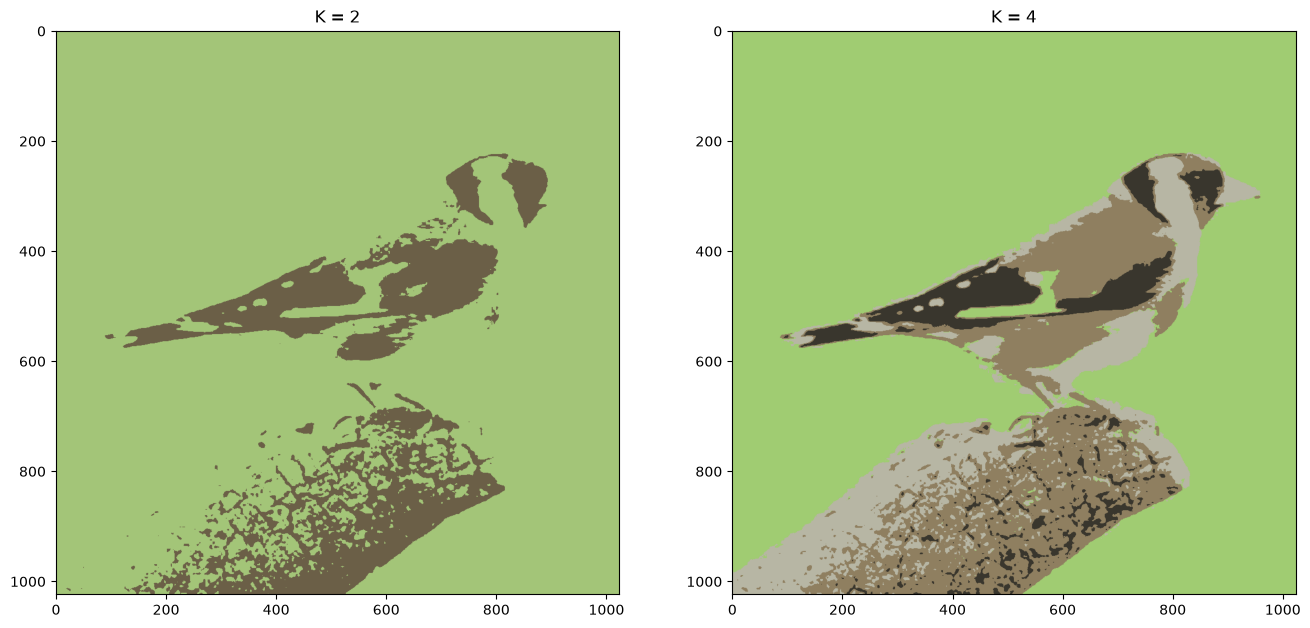

## 1-3. explain the differences between the two methods under the same K.
![](images/7.4_result.PNG)

[[152.83148879 173.98314888 107.99180036 134.07773144 187.17762218]
 [158.39470535 194.03927888 120.17931344 120.88667445  61.061527  ]]
[[157.91636464 192.79181697 112.34710071  45.83815441 124.40030819]
 [167.56876413 206.1119347  123.01275663 169.22354114 211.84469799]
 [114.06025221 101.95243056  75.90147062 173.15969546 137.92093139]
 [166.10897179 199.70963517 129.65799926 168.03508888  51.48023265]]
[[162.5144031  208.50958987 120.55398876 218.63009691 211.68209769]
 [156.2929696  200.4145167  113.50683415  60.08721137  59.81022864]
 [ 46.47415021  47.59712118  45.77163642 116.96371062 136.49969581]
 [172.88001422 212.23296661 127.14108733 128.55484538 218.32290827]
 [167.76348845 201.33640696 132.8711444  184.54122634  51.79548033]
 [160.97874406 142.68021314 101.96807564 122.49429014 154.48927378]
 [132.81423678 120.4519669   91.17297767 218.42015635 127.4199983 ]
 [159.54718492 194.8529202  113.13221915  36.65547216 183.67575461]]
[[164.75330683 208.24311161 110.98378804  82.

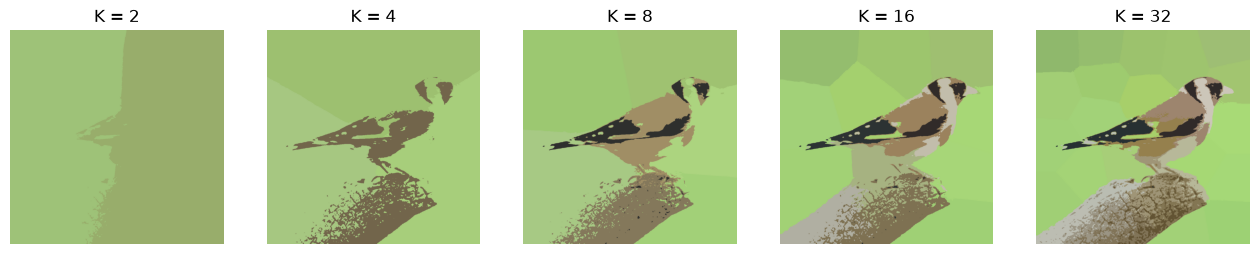

In [22]:
# ============================================================
# 【第一部分】取得圖片尺寸（Image Shape）
# ============================================================

# h：圖片高度
# w：圖片寬度
# c：圖片顏色通道數
h, w, c = img.shape


# ============================================================
# 【第二部分】建立新的特徵陣列（RGB + 座標資訊）
# ============================================================

# 建立一個全為 0 的三維陣列
# 尺寸為 (h, w, c+2)
# c+2 的意思是：
# 原本每個像素有 c 個顏色通道，再加上 2 個位置特徵
Z = np.zeros((h, w, c+2))

# 逐列走訪圖片
for h in range(len(img)):

    # 逐欄走訪每一列中的像素
    for w in range(len(img[h])):

        # 將原本像素的顏色值，加入座標資訊
        # 這裡加入的是 [h/4] 和 [w/4]
        # 也就是將位置縮小 4 倍後再放進特徵中
        Z[h][w] = np.append(img[h][w], [[h/4], [w/4]])

# 將三維陣列轉成二維陣列
# -1：讓 NumPy 自動計算總列數
# 5：每個像素最終有 5 個特徵（例如 RGB + 兩個座標）
Z = Z.reshape(-1, 5)


# ============================================================
# 【第三部分】設定 K-Means 分群數量
# ============================================================

# 準備測試不同的 K 值
# 分別為 2、4、8、16、32
Ks = [2,4,8,16,32]

# 建立繪圖視窗
# figsize=(16,12) 代表圖形顯示大小為 16 x 12 英吋
plt.figure(figsize=(16,12))


# ============================================================
# 【第四部分】依序執行不同 K 值的 K-Means 分群
# ============================================================

# i：目前迴圈索引
# K：目前使用的分群數量
for i, K in enumerate(Ks):

    # 執行 K-Means 分群
    # label：每個像素對應到的群組編號
    # center：每個群組的中心點
    label, center = km_clust(Z, K)

    # ========================================================
    # 【第五部分】將分群結果轉回圖片格式
    # ========================================================

    # 只取 center 的前三個欄位（顏色資訊）
    # 並轉換成 uint8，方便還原成影像像素格式
    center = np.uint8(center[:, :3])

    # 根據每個像素的群組標籤，取出對應的中心顏色
    # label.flatten()：將 label 攤平成一維陣列
    res = center[label.flatten()]

    # 將結果重新 reshape 成原始圖片形狀
    res = res.reshape((img.shape))

    # ========================================================
    # 【第六部分】顯示每個 K 值的分群結果
    # ========================================================

    # 建立 1 列 5 欄的子圖
    # i+1：表示目前放在第幾個位置
    plt.subplot(1, 5, i+1)

    # 關閉座標軸顯示
    plt.axis('off')

    # 設定每張子圖的標題，顯示目前 K 值
    plt.title("K = {}".format(K))

    # 顯示分群後的圖片
    plt.imshow(res)


# ============================================================
# 【第七部分】顯示所有圖片
# ============================================================

# 顯示整個比較結果
plt.show()